<a href="https://colab.research.google.com/github/ohona720hub/AI-Search-Algorithms/blob/main/UCS_Graph_Visualization_ipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

UCS Expanded Nodes: ['A', 'B', 'D', 'C', 'F', 'E', 'G']
Optimal Path: ['A', 'B', 'D', 'G']
Total Cost: 6


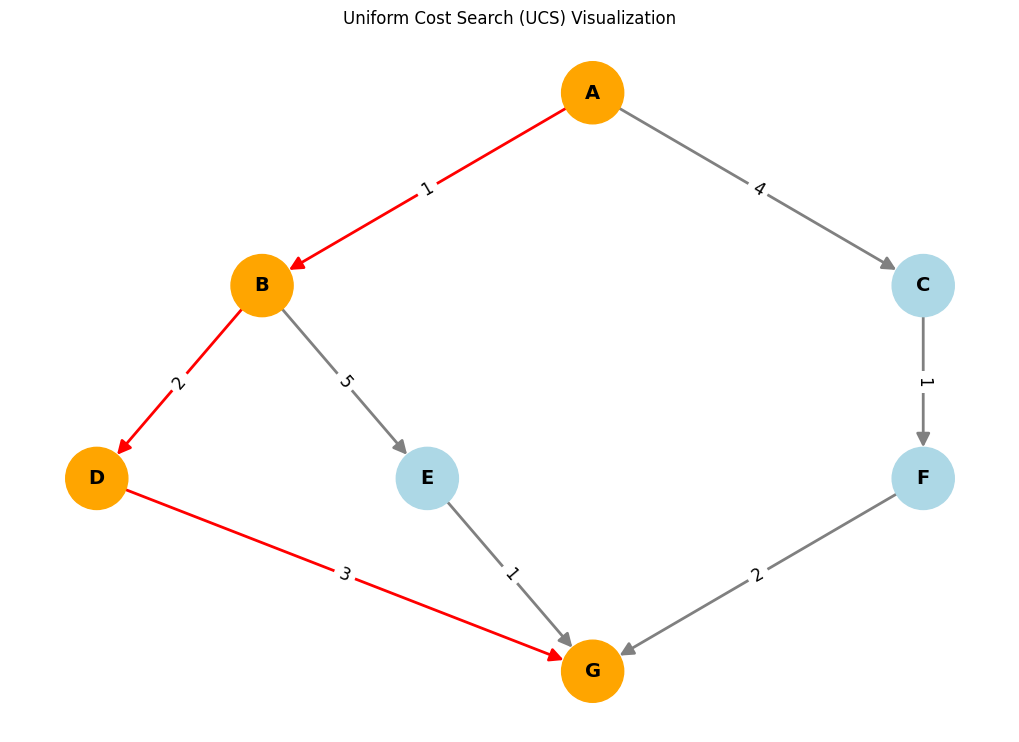

In [1]:
import networkx as nx
import matplotlib.pyplot as plt
import heapq
import itertools

# Create a weighted graph
graph = {
    'A': [('B', 1), ('C', 4)],
    'B': [('D', 2), ('E', 5)],
    'C': [('F', 1)],
    'D': [('G', 3)],
    'E': [('G', 1)],
    'F': [('G', 2)],
    'G': []
}

# Uniform Cost Search Algorithm
def ucs(graph, start, goal):
    counter = itertools.count()
    priority_queue = [(0, next(counter), start)]

    costs = {start: 0}
    parent = {start: None}
    visited = set()
    expanded = []

    while priority_queue:
        cost, _, node = heapq.heappop(priority_queue)

        if node in visited:
            continue

        visited.add(node)
        expanded.append(node)

        if node == goal:
            break

        for neighbor, edge_cost in graph[node]:
            new_cost = cost + edge_cost

            if neighbor not in costs or new_cost < costs[neighbor]:
                costs[neighbor] = new_cost
                parent[neighbor] = node

                heapq.heappush(
                    priority_queue,
                    (new_cost, next(counter), neighbor)
                )

    if goal not in visited:
        return expanded, None, None

    # Reconstruct the shortest path
    path = []
    current = goal

    while current is not None:
        path.append(current)
        current = parent[current]

    path.reverse()

    return expanded, path, costs[goal]


# Perform UCS
start_node = 'A'
goal_node = 'G'

expanded, path, total_cost = ucs(
    graph, start_node, goal_node
)

print("UCS Expanded Nodes:", expanded)
print("Optimal Path:", path)
print("Total Cost:", total_cost)


# Create weighted graph visualization
G = nx.DiGraph()

for node, neighbors in graph.items():
    for neighbor, weight in neighbors:
        G.add_edge(node, neighbor, weight=weight)

pos = {
    'A': (0, 2),
    'B': (-1, 1),
    'C': (1, 1),
    'D': (-1.5, 0),
    'E': (-0.5, 0),
    'F': (1, 0),
    'G': (0, -1)
}

path_edges = list(zip(path, path[1:]))

edge_colors = [
    'red' if edge in path_edges else 'gray'
    for edge in G.edges()
]

node_colors = [
    'orange' if node in path else 'lightblue'
    for node in G.nodes()
]

plt.figure(figsize=(10, 7))

nx.draw(
    G, pos,
    with_labels=True,
    node_color=node_colors,
    edge_color=edge_colors,
    node_size=2000,
    font_size=14,
    font_weight='bold',
    arrows=True,
    arrowsize=20,
    width=2
)

edge_labels = nx.get_edge_attributes(G, 'weight')
nx.draw_networkx_edge_labels(
    G, pos,
    edge_labels=edge_labels,
    font_size=12
)

plt.title("Uniform Cost Search (UCS) Visualization")
plt.show()